In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv("Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [6]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


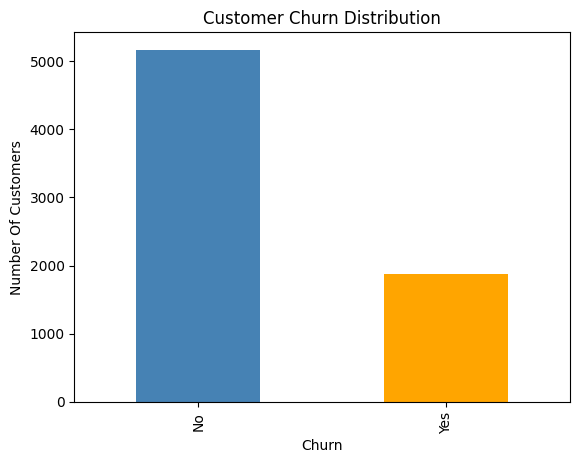

In [7]:

df['Churn'].value_counts().plot(kind = "bar",color = ['steelblue','orange'])
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number Of Customers")
plt.show()

In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors = "coerce")
df['TotalCharges'].isnull().sum()

np.int64(11)

In [9]:
df = df.dropna(subset = ["TotalCharges"])

In [10]:
df = df.drop('customerID',axis=1)

In [11]:
df['Churn'] = df['Churn'].map({"Yes":1,"No":0})

In [12]:
df['Churn'].value_counts()
df['Churn'].isnull().sum()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

In [13]:
fig = px.histogram(df,x="Contract" , color = "Churn", barmode = "group",
                   title = "Churn By Contract Type",
                   color_discrete_map = {0:'steelblue',1:'orange'},
                   height = 600, width = 800)
fig.show()

In [14]:
fig = px.histogram(df, x = "tenure", color = "Churn", nbins = 30,
                   title = "Churn By Tenure",
                   color_discrete_map = {0:'steelblue',1:'orange'},
                   height = 600 , width = 800)
fig.show()

In [15]:
fig = px.histogram(df , x = "MonthlyCharges" , color = "Churn" , nbins = 30,
                   title = "Churn By Monthly Charges",
                   color_discrete_map = {0:'steelblue',1:'orange'},
                   height = 600 , width = 800)
fig.show()

In [16]:
fig = px.pie(df,names = "Churn" , title = "Overall Churn Distribution" , hole = 0.4)
fig.update_layout(height = 500,
                  width = 700)
fig.show()

In [17]:
X = df.drop("Churn",axis = 1)
y = df["Churn"]

In [18]:
categorical_cols = X.select_dtypes(include = 'object').columns.tolist()
print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [19]:
X = pd.get_dummies(X,columns = categorical_cols,drop_first = True)

In [20]:
X.shape
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [21]:
from sklearn.preprocessing import StandardScaler
numeric_cols = ['tenure','MonthlyCharges','TotalCharges']
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42,stratify = y)
print(X_train.shape,X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(5625, 30) (1407, 30)
Churn
0    4130
1    1495
Name: count, dtype: int64
Churn
0    1033
1     374
Name: count, dtype: int64


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Build and train the model (balanced to match the Random Forest comparison below)
log_model = LogisticRegression(max_iter=1000, class_weight='balanced')
log_model.fit(X_train, y_train)

# Predict on test data
y_pred = log_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.7256574271499645

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407


Confusion Matrix:
 [[724 309]
 [ 77 297]]


In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7896233120113717

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407


Confusion Matrix:
 [[917 116]
 [180 194]]


In [25]:
rf_model_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)
rf_model_balanced.fit(X_train, y_train)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf_balanced))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf_balanced))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf_balanced))

Accuracy: 0.7867803837953091

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407


Confusion Matrix:
 [[924 109]
 [191 183]]


Model Comparison
Side-by-side comparison of all three models so the final model choice is justified by the numbers, not just by which was trained last.

In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def evaluate(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Churn)": precision_score(y_test, y_pred),
        "Recall (Churn)": recall_score(y_test, y_pred),
        "F1 (Churn)": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

results = pd.DataFrame([
    evaluate("Logistic Regression (balanced)", log_model, X_test, y_test),
    evaluate("Random Forest", rf_model, X_test, y_test),
    evaluate("Random Forest (balanced)", rf_model_balanced, X_test, y_test),
]).set_index("Model").round(3)

results

,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
Model,,,,,
Logistic Regression (balanced),0.726,0.490,0.794,0.606,0.835
Random Forest,0.790,0.626,0.519,0.567,0.816
Random Forest (balanced),0.787,0.627,0.489,0.550,0.817


Contract_Two year                -1.457428
tenure                           -1.256625
InternetService_Fiber optic       1.141081
Contract_One year                -0.787997
TotalCharges                      0.607643
MonthlyCharges                   -0.491789
PaymentMethod_Electronic check    0.407129
StreamingTV_Yes                   0.388301
StreamingMovies_Yes               0.371990
PhoneService_Yes                 -0.370125
OnlineSecurity_Yes               -0.346623
MultipleLines_Yes                 0.337164
TechSupport_Yes                  -0.304796
PaperlessBilling_Yes              0.255868
Dependents_Yes                   -0.229217
dtype: float64


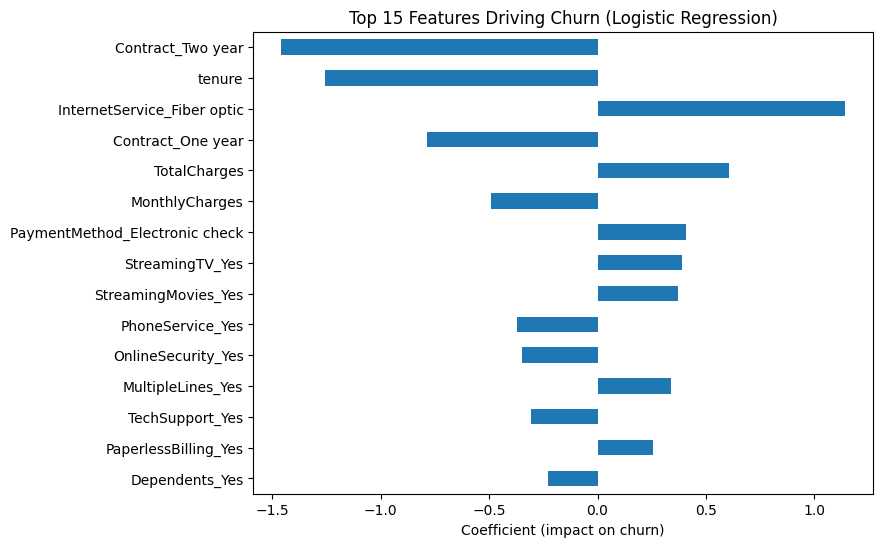

In [27]:
# Get feature importance (coefficients) from Logistic Regression
importance = pd.Series(log_model.coef_[0], index=X.columns)
importance_sorted = importance.sort_values(key=abs, ascending=False).head(15)

print(importance_sorted)

# Visualize
plt.figure(figsize=(8,6))
importance_sorted.plot(kind='barh')
plt.title('Top 15 Features Driving Churn (Logistic Regression)')
plt.xlabel('Coefficient (impact on churn)')
plt.gca().invert_yaxis()
plt.show()

In [28]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix

y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

ROC-AUC: 0.8354579621164667
[[724 309]
 [ 77 297]]


ROC Curve
Visualizing true positive vs. false positive rate across thresholds, alongside the AUC score above.

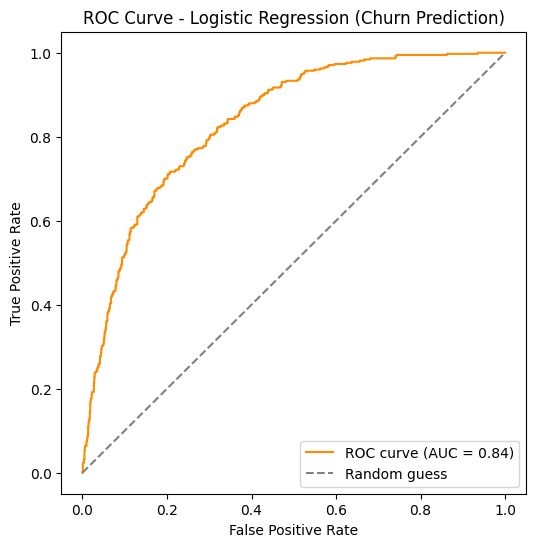

In [29]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (AUC = {roc_auc_score(y_test, y_prob):.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression (Churn Prediction)')
plt.legend(loc='lower right')
plt.show()